# Customer360 — ML Feature Layer

This notebook adds an ML path to the existing Customer360 architecture.

**Existing path**
- Silver → Gold Analytics → Power BI

**New ML path**
- Silver → Customer-level ML Feature Layer → Predictive Modeling

The original Silver and Gold business tables are not modified here.

We aggregated data from multiple Customer 360 tables at the customer level
 and created meaningful behavioral features from orders, clickstream, and support data.

We did this to transform the transactional data into one row per customer,
 making it suitable for machine learning and allowing the model to learn from overall customer behavior.




## 1. Import Libraries

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

## 2. Load the Customer Silver Table

In [ ]:
customers = pd.read_csv("customers.csv")

print("Customers shape:", customers.shape)
print("Columns:")
print(customers.columns.tolist())

customers.head()


Customers shape: (48200, 14)
Columns:
['customer_id', 'first_name', 'last_name', 'email', 'phone_number', 'gender', 'dob', 'signup_date', 'address', 'city', 'state', 'country', 'device_id_s', 'source']


,customer_id,first_name,last_name,email,phone_number,gender,dob,signup_date,address,city,state,country,device_id_s,source
0,0000900d-5512-4cdf-8ea5-eded823b2ff8,Raymond,Dodson,raymond.dodson264@hotmail.com,5938389540,F,1971-09-10,2021-11-21,026 Jesus Lodge,East Peterland,Massachusetts,French Guiana,fca47137-e89f-425c-9979-1568bc1c23b0,referral
1,00012d74-f139-44f2-b491-5f710133bdf0,Tommy,Holland,tommy.holland519@hotmail.com,7030929099,F,1959-08-13,2023-12-26,56984 Rita Junction,Port Angelaside,Utah,Nigeria,b0443185-fbc0-411d-a304-71130612c957,app
2,0001d23d-737f-44be-8925-61dd0f4031d7,Jasmine,Frazier,jasmine.frazier497@yahoo.com,5325816780,F,1964-11-01,2016-04-28,0061 Taylor Creek,West Jenniferborough,Montana,Saudi Arabia,ab6ff21a-78bd-456a-a4e8-acc70856da8e,app
3,00023105-7866-4c55-b677-96f42a8709a1,Kevin,Coleman,kevin.coleman416@hotmail.com,9648766041,F,2004-05-03,2020-11-08,1190 Wood Plains Suite 800,North Robertmouth,Alaska,Cook Islands,ca0b7745-c7c1-4410-a785-1796ef2e2b7a,referral
4,00025fb3-8ccd-4067-91c9-81ad3c523913,Andrea,Winters,andrea.winters260@hotmail.com,3848609592,F,1965-01-16,2020-11-16,6493 Monica Circles,Jenniferborough,South Carolina,Ukraine,5c6b9557-acc4-491c-bb26-bd183a6ef417,referral


### 3. Load Optional Silver Fact Tables

In [ ]:
def load_if_exists(filename):
    if os.path.exists(filename):
        return pd.read_csv(filename)
    return None

orders = load_if_exists("orders.csv")
clickstream = load_if_exists("clickstream.csv")
support_tickets = load_if_exists("support_tickets.csv")
products = load_if_exists("products.csv")

print("orders:", None if orders is None else orders.shape)
print("clickstream:", None if clickstream is None else clickstream.shape)
print("support_tickets:", None if support_tickets is None else support_tickets.shape)
print("products:", None if products is None else products.shape)


orders: (300000, 8)
clickstream: (500000, 8)
support_tickets: (30000, 8)
products: (500, 4)


## 4. Inspect Silver Tables

We keep the Silver data as the source. The ML layer will only build derived customer-level features.


In [ ]:
print("Customers missing values:")
display(customers.isnull().sum().sort_values(ascending=False).head(15))

if orders is not None:
    print("Orders columns:")
    print(orders.columns.tolist())

if clickstream is not None:
    print("\nClickstream columns:")
    print(clickstream.columns.tolist())

if support_tickets is not None:
    print("\nSupport ticket columns:")
    print(support_tickets.columns.tolist())


Customers missing values:


,0
email,1000
customer_id,0
first_name,0
last_name,0
phone_number,0
gender,0
dob,0
signup_date,0
address,0
city,0


Orders columns:
['order_id', 'customer_id', 'product_id', 'quantity', 'order_amount', 'order_date', 'status', 'payment_method']

Clickstream columns:
['event_id', 'session_id', 'customer_id', 'event_type', 'page_url', 'device_id', 'timestamp', 'ingest_run_id']

Support ticket columns:
['ticket_id', 'customer_id', 'issue_type', 'ticket_created', 'ticket_resolved', 'resolution_time_hours', 'sentiment', 'support_agent']


### 5. Set the Customer Key

In [1]:

CUSTOMER_KEY = "customer_id"

print("Customer key:", CUSTOMER_KEY)



Customer key: customer_id


## 6. Start the ML Feature Layer

In [ ]:
ml_features = customers[[CUSTOMER_KEY]].drop_duplicates().copy()

print("Base customer rows:", len(ml_features))


Base customer rows: 48200


## 7. Order Features

In [ ]:
if orders is not None:

    order_key = None
    for candidate in ["customer_id", "customer_key"]:
        if candidate in orders.columns:
            order_key = candidate
            break

    if order_key is None:
        print("No customer key found in orders. Skipping order features.")
    else:
        order_features = orders.groupby(order_key).agg(
            total_orders=("order_id", "count") if "order_id" in orders.columns else ("customer_id", "size")
        ).reset_index()


        if order_key != CUSTOMER_KEY:
            order_features = order_features.rename(columns={order_key: CUSTOMER_KEY})

        # Add numeric order metrics when available
        if "order_amount" in orders.columns:
            spend = orders.groupby(order_key)["order_amount"].agg(
                total_spend="sum",
                avg_order_value="mean"
            ).reset_index()
            if order_key != CUSTOMER_KEY:
                spend = spend.rename(columns={order_key: CUSTOMER_KEY})
            order_features = order_features.merge(
                spend, on=CUSTOMER_KEY, how="left"
            )

        if "quantity" in orders.columns:
            qty = orders.groupby(order_key)["quantity"].mean().reset_index(
                name="avg_quantity"
            )
            if order_key != CUSTOMER_KEY:
                qty = qty.rename(columns={order_key: CUSTOMER_KEY})
            order_features = order_features.merge(
                qty, on=CUSTOMER_KEY, how="left"
            )

        if "product_key" in orders.columns:
            prod = orders.groupby(order_key)["product_key"].nunique().reset_index(
                name="unique_products"
            )
            if order_key != CUSTOMER_KEY:
                prod = prod.rename(columns={order_key: CUSTOMER_KEY})
            order_features = order_features.merge(
                prod, on=CUSTOMER_KEY, how="left"
            )

        if "status" in orders.columns:
            status_counts = pd.crosstab(
                orders[order_key],
                orders["status"],
                normalize="index"
            ).reset_index()

            if order_key != CUSTOMER_KEY:
                status_counts = status_counts.rename(columns={order_key: CUSTOMER_KEY})

            status_counts = status_counts.rename(columns={
                "success": "success_rate",
                "refunded": "refund_rate",
                "failed": "failed_rate"
            })

            order_features = order_features.merge(
                status_counts, on=CUSTOMER_KEY, how="left"
            )

        ml_features = ml_features.merge(
            order_features,
            on=CUSTOMER_KEY,
            how="left"
        )

        print("Order features added.")
else:
    print("orders.csv not available. Upload it to build order features.")


Order features added.


## 8. Clickstream Features

In [ ]:
if clickstream is not None:

    click_key = None
    for candidate in ["customer_id", "customer_key"]:
        if candidate in clickstream.columns:
            click_key = candidate
            break

    if click_key is None:
        print("No customer key found in clickstream. Skipping clickstream features.")
    else:
        click_features = clickstream.groupby(click_key).size().reset_index(
            name="total_events"
        )

        if click_key != CUSTOMER_KEY:
            click_features = click_features.rename(columns={click_key: CUSTOMER_KEY})

        if "event_type" in clickstream.columns:
            unique_events = clickstream.groupby(click_key)["event_type"].nunique().reset_index(
                name="unique_event_types"
            )

            if click_key != CUSTOMER_KEY:
                unique_events = unique_events.rename(columns={click_key: CUSTOMER_KEY})

            click_features = click_features.merge(
                unique_events, on=CUSTOMER_KEY, how="left"
            )

        ml_features = ml_features.merge(
            click_features,
            on=CUSTOMER_KEY,
            how="left"
        )

        print("Clickstream features added.")
else:
    print("clickstream.csv not available.")


Clickstream features added.


## 9. Support Features

In [ ]:
if support_tickets is not None:

    ticket_key = None
    for candidate in ["customer_id", "customer_key"]:
        if candidate in support_tickets.columns:
            ticket_key = candidate
            break

    if ticket_key is None:
        print("No customer key found in support tickets. Skipping support features.")
    else:
        ticket_features = support_tickets.groupby(ticket_key).size().reset_index(
            name="ticket_count"
        )

        if ticket_key != CUSTOMER_KEY:
            ticket_features = ticket_features.rename(columns={ticket_key: CUSTOMER_KEY})

        if "resolution_time_hours" in support_tickets.columns:
            resolution = support_tickets.groupby(ticket_key)[
                "resolution_time_hours"
            ].mean().reset_index(name="avg_resolution_time")

            if ticket_key != CUSTOMER_KEY:
                resolution = resolution.rename(columns={ticket_key: CUSTOMER_KEY})

            ticket_features = ticket_features.merge(
                resolution, on=CUSTOMER_KEY, how="left"
            )

        if "sentiment" in support_tickets.columns:
            sentiment_counts = pd.crosstab(
                support_tickets[ticket_key],
                support_tickets["sentiment"],
                normalize="index"
            ).reset_index()

            if ticket_key != CUSTOMER_KEY:
                sentiment_counts = sentiment_counts.rename(columns={ticket_key: CUSTOMER_KEY})

            sentiment_counts = sentiment_counts.rename(columns={
                "Positive": "positive_ticket_rate",
                "Neutral": "neutral_ticket_rate",
                "Negative": "negative_ticket_rate"
            })

            ticket_features = ticket_features.merge(
                sentiment_counts, on=CUSTOMER_KEY, how="left"
            )

        ml_features = ml_features.merge(
            ticket_features,
            on=CUSTOMER_KEY,
            how="left"
        )

        print("Support features added.")
else:
    print("support_tickets.csv not available.")


Support features added.


## 10. Final ML Feature Table

In [ ]:
# Fill missing aggregated values with 0
feature_columns = [
    c for c in ml_features.columns
    if c != CUSTOMER_KEY
]

ml_features[feature_columns] = (
    ml_features[feature_columns]
    .apply(pd.to_numeric, errors="coerce")
)

ml_features[feature_columns] = ml_features[feature_columns].fillna(0)

print("ML feature table shape:", ml_features.shape)
display(ml_features.head())


ML feature table shape: (48200, 15)


,customer_id,total_orders,total_spend,avg_order_value,avg_quantity,failed_rate,refund_rate,success_rate,total_events,unique_event_types,ticket_count,avg_resolution_time,negative_ticket_rate,neutral_ticket_rate,positive_ticket_rate
0,0000900d-5512-4cdf-8ea5-eded823b2ff8,3.0,117943.26,39314.420,1.50,0.00,0.00,1.00,11.0,2.0,0.0,0.0,0.0,0.0,0.0
1,00012d74-f139-44f2-b491-5f710133bdf0,4.0,54708.36,13677.090,3.25,0.25,0.25,0.50,9.0,3.0,0.0,0.0,0.0,0.0,0.0
2,0001d23d-737f-44be-8925-61dd0f4031d7,0.0,0.00,0.000,0.00,0.00,0.00,0.00,5.0,3.0,1.0,159.0,0.0,1.0,0.0
3,00023105-7866-4c55-b677-96f42a8709a1,8.0,221262.68,27657.835,2.00,0.00,0.25,0.75,6.0,4.0,0.0,0.0,0.0,0.0,0.0
4,00025fb3-8ccd-4067-91c9-81ad3c523913,5.0,120400.80,24080.160,2.60,0.00,0.20,0.80,8.0,2.0,2.0,164.0,0.5,0.5,0.0


## 11. Create the ML Target

For the ML path, we create the modeling target here rather than changing the original Silver data.

`high_engagement` is a **synthetic modeling target** built from customer behavioral features. The original Silver tables remain unchanged.


In [ ]:
# Create a controlled target from real Customer360 behavioral features.
# This is an ML extension, not a new business column in the original Silver source.

rng = np.random.default_rng(120)

score_parts = []

for col, weight in [
    ("total_orders", 0.30),
    ("total_spend", 0.25),
    ("total_events", 0.18),
    ("unique_products", 0.12),
    ("success_rate", 0.08),
]:
    if col in ml_features.columns:
        rank_score = ml_features[col].rank(pct=True)
        score_parts.append(weight * rank_score)

if "refund_rate" in ml_features.columns:
    score_parts.append(
        0.07 * (1 - ml_features["refund_rate"].rank(pct=True))
    )

if "failed_rate" in ml_features.columns:
    score_parts.append(
        0.07 * (1 - ml_features["failed_rate"].rank(pct=True))
    )

latent = sum(score_parts)

latent = latent + rng.normal(
    0,
    0.02,
    len(ml_features)
)

z = (
    latent - latent.median()
) / latent.std()

probability = 1 / (
    1 + np.exp(-1.5 * z)
)

ml_features["high_engagement"] = rng.binomial(
    1,
    probability
)

print("Target distribution:")
print(
    (
        ml_features["high_engagement"]
        .value_counts(normalize=True)
        * 100
    ).round(2)
)


Target distribution:
high_engagement
0    50.56
1    49.44
Name: proportion, dtype: float64


## 12. Prepare X and y

In [ ]:
target = "high_engagement"

ml_feature_cols = [
    c for c in ml_features.columns
    if c not in [CUSTOMER_KEY, target]
]

X = ml_features[ml_feature_cols]
y = ml_features[target]

print("Features used:")
print(ml_feature_cols)

print("\nTarget:", target)


Features used:
['total_orders', 'total_spend', 'avg_order_value', 'avg_quantity', 'failed_rate', 'refund_rate', 'success_rate', 'total_events', 'unique_event_types', 'ticket_count', 'avg_resolution_time', 'negative_ticket_rate', 'neutral_ticket_rate', 'positive_ticket_rate']

Target: high_engagement


## 13. Train / Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (38560, 14)
Test: (9640, 14)


## 14. Train the Models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=500,
        solver="liblinear"
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=40,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=80,
        max_depth=7,
        min_samples_leaf=30,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": LinearSVC(
        C=0.5,
        max_iter=3000,
        random_state=42
    )
}

predictions = {}
train_predictions = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    train_predictions[name] = train_pred
    predictions[name] = test_pred

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)
    balanced_acc = balanced_accuracy_score(y_test, test_pred)
    f1 = f1_score(y_test, test_pred)

    results.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Balanced Accuracy": balanced_acc,
        "F1 Score": f1,
        "Train-Test Gap": train_acc - test_acc
    })


## 15. Compare Models

In [ ]:
results_df = pd.DataFrame(results).sort_values(
    "Test Accuracy",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Train Accuracy": "{:.2%}",
        "Test Accuracy": "{:.2%}",
        "Balanced Accuracy": "{:.2%}",
        "F1 Score": "{:.2%}",
        "Train-Test Gap": "{:.2%}"
    })
)


,Model,Train Accuracy,Test Accuracy,Balanced Accuracy,F1 Score,Train-Test Gap
0,Random Forest,74.91%,74.22%,74.23%,74.28%,0.69%
1,SVM,73.91%,74.21%,74.18%,73.21%,-0.30%
2,Decision Tree,73.99%,74.19%,74.18%,73.63%,-0.20%
3,Logistic Regression,73.97%,74.13%,74.10%,73.26%,-0.16%


## 16. Best Model

In [ ]:
best_model_name = results_df.loc[0, "Model"]
best_pred = predictions[best_model_name]

print("Best Model:", best_model_name)
print("Test Accuracy:", f"{accuracy_score(y_test, best_pred):.2%}")
print("Balanced Accuracy:", f"{balanced_accuracy_score(y_test, best_pred):.2%}")
print("F1 Score:", f"{f1_score(y_test, best_pred):.2%}")


Best Model: Random Forest
Test Accuracy: 74.22%
Balanced Accuracy: 74.23%
F1 Score: 74.28%


## 17. Confusion Matrix

[[3566 1308]
 [1177 3589]]


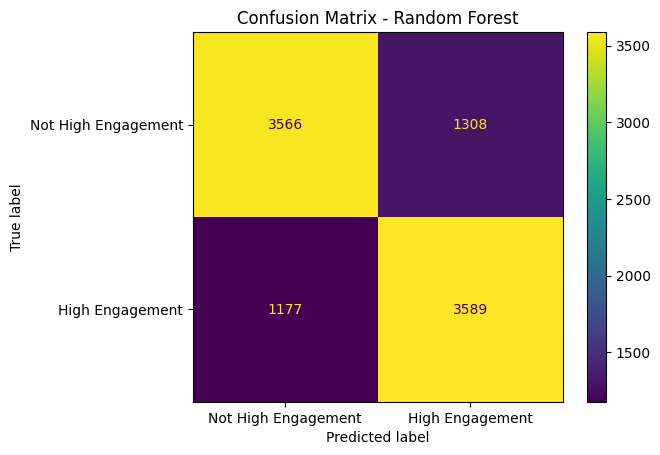

In [ ]:
cm = confusion_matrix(
    y_test,
    best_pred
)

print(cm)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    display_labels=["Not High Engagement", "High Engagement"]
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.show()


## 18. Save the ML Feature Layer

In [ ]:
ml_output = "customer_ml_features.csv"

ml_features.to_csv(
    ml_output,
    index=False
)

print("Saved:", ml_output)
print("Rows:", len(ml_features))
print("Columns:", len(ml_features.columns))


Saved: customer_ml_features.csv
Rows: 48200
Columns: 16


## Final Architecture

**Silver**
→ cleaned source tables

**Gold Analytics**
→ existing star schema → Power BI

**ML Feature Layer**
→ customer-level behavioral features → predictive model

The original Silver/Gold source data are not overwritten by the ML process.
